# Global Insulin Resistance 2005-2024


In [2]:
import pandas as pd 
df = pd.read_csv(r"C:\Users\Nitro\OneDrive\Desktop\Projects\Global Insulin Analysis Project\Data\Global_Insulin_Resistance2005-2024(Orignal Data).csv")
df.head()

,ID,Country,Year,Age,Gender,Age_Group,HbA1c,HDL,LDL,TG,TG_HDL_Ratio,Fasting_Insulin,HOMA_IR,Diabetic,Insulin_Resistant,Heart_Risk
0,1,United States,2005,67,Female,Elderly,7.32,45.24,120.60,135.67,3.00,8.95,2.19,1,0,Low
1,2,United States,2005,64,Female,Elderly,7.09,38.66,186.41,226.44,5.86,10.55,2.58,1,1,High
2,3,United States,2005,28,Male,Adult,7.56,41.43,184.71,162.73,3.93,9.41,2.30,1,0,High
3,4,United States,2005,8,Male,Child,5.88,26.34,165.12,229.17,8.70,12.75,3.12,0,1,High
4,5,United States,2005,11,Female,Child,7.55,60.34,109.07,182.53,3.03,8.22,2.01,1,0,Low


In [3]:
# HbA1c  --> measures the average of sugar in blood in the last three months   (Average blood sugar level)
# HDL --> High-Density Lipoprotein   (Good cholesterol)
# LDL --> High-Density Lipoprotei    (Bad cholesterol)
# TG --> Triglycerides  
# TG_HDL-Ratio   if it high it means that there is a insulin resistance  
# Fasting_Insulin 
# HOMA_IR  if the number > 2.5 there is a danger on the patient 

In [6]:
# to see all countries
df['Country'].unique()
# there is many countries ...

array(['United States', 'China', 'India', 'Indonesia', 'Pakistan',
       'Brazil', 'Nigeria', 'Bangladesh', 'Russia', 'Mexico', 'Japan',
       'Ethiopia', 'Philippines', 'Egypt', 'Vietnam', 'DR Congo',
       'Turkey', 'Iran', 'Germany', 'Thailand', 'United Kingdom',
       'France', 'Italy', 'South Africa', 'Tanzania', 'Myanmar', 'Kenya',
       'South Korea', 'Colombia', 'Spain', 'Uganda', 'Argentina',
       'Algeria', 'Sudan', 'Ukraine', 'Iraq', 'Afghanistan', 'Poland',
       'Canada', 'Morocco', 'Saudi Arabia', 'Uzbekistan', 'Peru',
       'Malaysia', 'Angola', 'Ghana', 'Mozambique', 'Yemen', 'Nepal',
       'Venezuela', 'Madagascar', 'Cameroon', "Côte d'Ivoire",
       'North Korea', 'Australia', 'Niger', 'Sri Lanka', 'Burkina Faso',
       'Mali', 'Romania', 'Malawi', 'Chile', 'Kazakhstan', 'Zambia',
       'Guatemala', 'Ecuador', 'Syria', 'Netherlands', 'Senegal',
       'Cambodia', 'Chad', 'Somalia', 'Zimbabwe', 'Guinea', 'Rwanda',
       'Benin', 'Burundi', 'Tunisia', 'Bol

In [8]:
# need to know there is nulls and how much 
df.isnull().sum()
# Very good 

ID                   0
Country              0
Year                 0
Age                  0
Gender               0
Age_Group            0
HbA1c                0
HDL                  0
LDL                  0
TG                   0
TG_HDL_Ratio         0
Fasting_Insulin      0
HOMA_IR              0
Diabetic             0
Insulin_Resistant    0
Heart_Risk           0
dtype: int64

In [10]:
# there is duplicate data ?
df.duplicated().sum()
# No dublicates ...

np.int64(0)

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 190000 entries, 0 to 189999
Data columns (total 16 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   ID                 190000 non-null  int64  
 1   Country            190000 non-null  object 
 2   Year               190000 non-null  int64  
 3   Age                190000 non-null  int64  
 4   Gender             190000 non-null  object 
 5   Age_Group          190000 non-null  object 
 6   HbA1c              190000 non-null  float64
 7   HDL                190000 non-null  float64
 8   LDL                190000 non-null  float64
 9   TG                 190000 non-null  float64
 10  TG_HDL_Ratio       190000 non-null  float64
 11  Fasting_Insulin    190000 non-null  float64
 12  HOMA_IR            190000 non-null  float64
 13  Diabetic           190000 non-null  int64  
 14  Insulin_Resistant  190000 non-null  int64  
 15  Heart_Risk         190000 non-null  object 
dtypes:

 Total Removed : 52


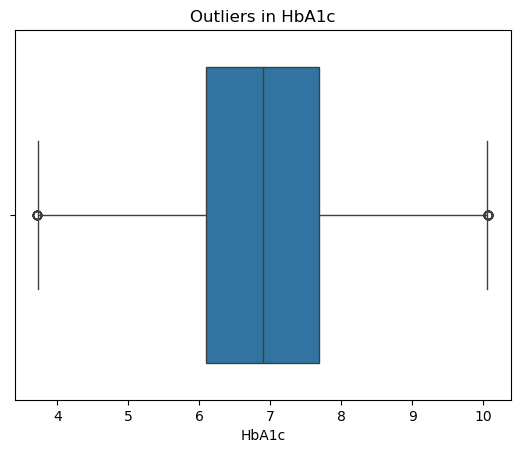

In [18]:
# Outliers Detection
import seaborn as sns
import matplotlib.pyplot as plt

Q1 = df['HbA1c'].quantile(0.25)
Q3 = df['HbA1c'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR


df_clean = df[(df['HbA1c'] >= lower_bound) & (df['HbA1c'] <= upper_bound)]

print(f" Total Removed : {len(df) - len(df_clean)}")
# Total Removed : 1227


sns.boxplot(x=df['HbA1c'])
plt.title('Outliers in HbA1c')
plt.show()


df = df_clean.copy()

In [19]:
# Make a new column of the insulin status
import numpy as np

conditions = [
    (df['HOMA_IR'] < 1.9),
    (df['HOMA_IR'] >= 1.9) & (df['HOMA_IR'] <= 2.9),
    (df['HOMA_IR'] > 2.9)
]


values = ['Optimal', 'Early Insulin Resistance', 'Significant Insulin Resistance']

df['Insulin_Status'] = np.select(conditions, values, default='Unknown')

In [20]:
df.head(15)

,ID,Country,Year,Age,Gender,Age_Group,HbA1c,HDL,LDL,TG,TG_HDL_Ratio,Fasting_Insulin,HOMA_IR,Diabetic,Insulin_Resistant,Heart_Risk,Insulin_Status
0,1,United States,2005,67,Female,Elderly,7.32,45.24,120.60,135.67,3.00,8.95,2.19,1,0,Low,Early Insulin Resistance
1,2,United States,2005,64,Female,Elderly,7.09,38.66,186.41,226.44,5.86,10.55,2.58,1,1,High,Early Insulin Resistance
2,3,United States,2005,28,Male,Adult,7.56,41.43,184.71,162.73,3.93,9.41,2.30,1,0,High,Early Insulin Resistance
3,4,United States,2005,8,Male,Child,5.88,26.34,165.12,229.17,8.70,12.75,3.12,0,1,High,Significant Insulin Resistance
4,5,United States,2005,11,Female,Child,7.55,60.34,109.07,182.53,3.03,8.22,2.01,1,0,Low,Early Insulin Resistance
5,6,United States,2005,9,Female,Child,6.26,53.94,154.98,108.93,2.02,2.47,0.60,0,0,Medium,Optimal
6,7,United States,2005,8,Female,Child,4.76,36.30,159.85,114.61,3.16,7.56,1.85,0,0,Medium,Optimal
7,8,United States,2005,35,Male,Adult,8.21,29.22,152.46,223.97,7.67,5.04,1.23,1,0,High,Optimal
8,9,United States,2005,77,Female,Elderly,7.65,52.51,146.07,290.27,5.53,7.18,1.75,1,0,High,Optimal
9,10,United States,2005,34,Female,Adult,5.87,52.57,112.89,250.03,4.76,9.69,2.37,0,0,High,Early Insulin Resistance


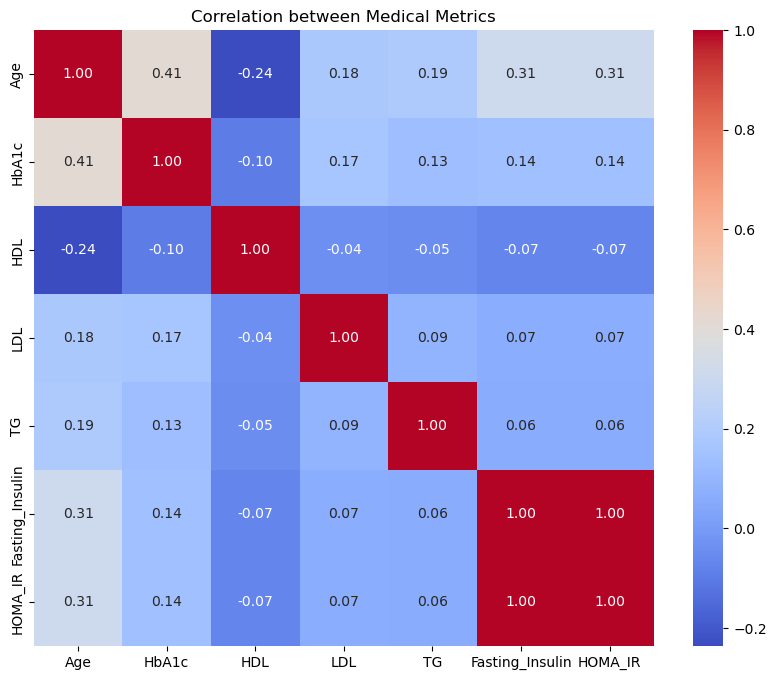

In [22]:
# Numberic column only 
numeric_cols = df[['Age', 'HbA1c', 'HDL', 'LDL', 'TG', 'Fasting_Insulin', 'HOMA_IR']]
corr = numeric_cols.corr()

# The Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation between Medical Metrics')
plt.show()

# Analysis Summary: A strong positive correlation (1.00) exists between Fasting Insulin and HOMA-IR, confirming data consistency.
# Insights: Age shows a moderate positive correlation (0.41) with HbA1c, while HDL (Good Cholesterol) decreases as metabolic risks increase.

In [23]:
# Saving ..
df.to_csv('Global_Insulin_Final_Cleaned.csv', index=False)
